# 廣告活動預算分配分析

**問題**：在各客戶總預算不變的前提下，如何重新分配廣告預算，提升 ROAS 且轉換數不減少？

**主要發現**（Conversions 型廣告，整體 ROAS 8.01）
- 約 52% 的預算投放在 Mobile，但 Mobile ROAS 只有 4.68；Desktop 為 13.36，差距主要來自轉換率
- Facebook ROAS 最高（14.19），主因是點擊成本低；Google Ads 與 LinkedIn 點擊成本高，ROAS 偏低
- 素材格式的影響較小，且最佳素材因產業而異

**建議**
1. 將約 10% 的 Mobile 預算移到 Desktop：預估營收至少增加約 510 萬，轉換數增加約 1.1 萬筆
2. 將約 10% 的 Google Ads 預算移到 Facebook：預估營收至少增加約 234 萬，轉換數增加約 4,400 筆


## 分析計畫

**主要指標**：ROAS　

**護欄指標**：轉換數

**分析方法**：只看 Conversions 型廣告；每個分組至少 30 筆 campaign 才下結論

**分析面向**：平台、素材格式、裝置、產業（先看整體結論，再看各產業是否一致）

| 子問題 | 假設 | 為什麼想知道 |
|---|---|---|
| 1. 哪個平台 ROAS 最高？ | Facebook 最高，因為受眾鎖定精準（類似受眾、pixel），CVR 高 | 決定平台間的預算移動 |
| 2. 哪種素材格式 ROAS 最高？ | Video 最高，因為能呈現更多產品特色（CVR 高），且較吸睛（CTR 高 → CPC 低） | 決定各產業的素材方向 |
| 3. 哪種裝置 ROAS 最高？ | Mobile 最高，因為在手機上下單方便，CVR 高 | 決定裝置間的預算移動 |
| 4. 高 ROAS 組合加碼後，ROAS 與 CPA 會不會變差？ | 不會，因為這些組合目前花費不大，離受眾飽和還遠 | 確認高效組合是否能承接更多預算 |



## 1. 資料理解

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)

plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang TC', 'Heiti TC']
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv(Path('data') / 'tech_advertising_campaigns_dataset.csv')
print(df.shape)

(10000, 41)


In [2]:
print(df.columns.tolist())

['campaign_id', 'campaign_objective', 'platform', 'ad_placement', 'device_type', 'operating_system', 'creative_format', 'creative_size', 'ad_copy_length', 'has_call_to_action', 'creative_emotion', 'creative_age_days', 'target_audience_age', 'target_audience_gender', 'audience_interest_category', 'income_bracket', 'purchase_intent_score', 'retargeting_flag', 'start_date', 'quarter', 'day_of_week', 'hour_of_day', 'campaign_day', 'quality_score', 'actual_cpc', 'impressions', 'clicks', 'conversions', 'ad_spend', 'revenue', 'bounce_rate', 'avg_session_duration_seconds', 'pages_per_session', 'industry_vertical', 'budget_tier', 'CTR', 'CPC', 'conversion_rate', 'CPA', 'ROAS', 'profit']


In [3]:
# 檢查有沒有缺值
na_counts = df.isna().sum()
print(na_counts[na_counts > 0])

Series([], dtype: int64)


In [4]:
#各廣告目標的筆數，確認 Conversions 筆數
print(df['campaign_objective'].value_counts())

campaign_objective
Lead Generation    3563
Conversions        2946
Brand Awareness    2043
App Installs        746
Engagement          702
Name: count, dtype: int64


- ROAS 是轉換型廣告的成效指標，在後續 ROAS 歸因上也比較可信，因此後續分析只保留 Conversions 型廣告，共 2946 筆，占全部的 29%。

In [5]:
#只看 Conversions 時，平台 × 素材的 campaign 數
conv = df[df['campaign_objective'] == 'Conversions']
print(pd.crosstab(conv['platform'], conv['creative_format']))

creative_format  Carousel  Image  Interactive  Story  Text  Video
platform                                                         
Facebook              110    254           41     30    56    227
Google Ads            137    312           62     47    56    266
Instagram              43     87           19     10    20     70
LinkedIn               68    154           31     22    41    114
TikTok                 47    142           23     20    26    115
Twitter                36    105           25     13    28     89


- 各平台的 campaign 數量差異大，Interactive、Story、Text 在多數平台低於 30 筆，這些組合的結論可信度較低

## 2. 定義範圍與指標

In [56]:
def analyze_performance(df, group_col):
    result = df.groupby(group_col ,observed = True).agg(
        campaigns = ('campaign_id', 'nunique'),
        clicks = ('clicks','sum'),
        impressions = ('impressions','sum'),
        spend = ('ad_spend', 'sum'),
        revenue = ('revenue', 'sum'),
        conversions = ('conversions','sum')
    )
    
    result['CTR'] = result['clicks'] / result['impressions']
    result['CPA'] = result['spend'] / result['conversions']
    result['CPC'] = result['spend'] / result['clicks']
    result['CVR'] = result['conversions'] / result['clicks']
    result['ROAS'] = result['revenue'] / result['spend']
    result['revenue_per_conversion'] = result['revenue'] / result['conversions']

    metrics = ['campaigns', 'spend', 'ROAS', 'CPA', 'CPC', 'CVR', 'revenue_per_conversion', 'CTR']
    
    return result[metrics].sort_index().round(4)

## 3. 基準線
先算出整體 ROAS，作為後續所有組合的比較標準。

In [57]:
# 整體 ROAS：所有 Conversions 廣告的總營收 / 總花費
overall_roas = conv['revenue'].sum() / conv['ad_spend'].sum()
print(f'整體 ROAS 為：{round(overall_roas, 2)}')

整體 ROAS 為：8.01


## 4. 子問題 1：平台
**假設**：Facebook 的 ROAS 最高，因為受眾鎖定精準，CVR 高。

In [58]:
analyze_performance(conv, 'platform')

,campaigns,spend,ROAS,CPA,CPC,CVR,revenue_per_conversion,CTR
platform,,,,,,,,
Facebook,718,1803137.23,14.1861,30.2464,1.7171,0.0568,429.0789,0.0243
Google Ads,880,5396951.33,6.3664,66.9174,4.1399,0.0619,426.0215,0.0189
Instagram,249,868414.90,8.4297,52.6121,2.2927,0.0436,443.5041,0.0217
LinkedIn,430,2825411.79,4.4272,97.6401,6.5335,0.0669,432.2700,0.0196
TikTok,373,784048.13,11.6936,34.1857,1.3022,0.0381,399.7522,0.0218
Twitter,296,868878.50,13.2738,31.9265,1.5549,0.0487,423.7838,0.0283


- 假設部分成立：Facebook 的 ROAS 最高（14.19），但 CVR 不是最高。
- Facebook 勝出是因為 CPC 低，且在 CPC 前三低（Facebook、TikTok、Twitter）的平台中 CVR 最高。
- 各平台 ROAS 的差距主要來自 CPC：ROAS 最低的 LinkedIn 和 Google Ads，CPC 也最高。
- 由於 Facebook 的優勢來自 CPC 低，且在低 CPC 平台中 CVR 最高，後續加碼時需同時觀察 CPC 與 CVR：若 CPC 上升而 CVR 未跟著提升，ROAS 就會下降，就要停止加碼。

In [9]:
# 各產業 × 平台的 ROAS
industry = conv.groupby(['industry_vertical', 'platform'])[['revenue', 'ad_spend']].sum()
industry['ROAS'] = industry['revenue'] / industry['ad_spend']
print(industry['ROAS'].unstack().round(2))

platform           Facebook  Google Ads  Instagram  LinkedIn  TikTok  Twitter
industry_vertical                                                            
E-commerce             9.14        4.00       4.43      3.72    9.46     8.49
Education             15.82        5.21       8.27      3.95   15.75    11.50
Finance               21.72       10.16      14.29      6.22   16.60    27.59
Gaming                 3.42        1.14       1.91      0.64    3.47     5.66
Healthcare            15.86        7.72      10.75      5.26   11.85    10.76
SaaS                  12.14        6.02       8.72      4.14    9.99    12.93


In [61]:
# 各產業 × 平台的 campaign 數
print(conv.groupby(['industry_vertical', 'platform']).size().unstack())

platform           Facebook  Google Ads  Instagram  LinkedIn  TikTok  Twitter
industry_vertical                                                            
E-commerce              183         226         60        99     101       85
Education                77          97         28        41      37       30
Finance                 119         142         32        55      57       38
Gaming                   31          36         15        26      14       10
Healthcare              137         159         45       106      65       67
SaaS                    171         220         69       103      99       66


**產業檢查**

在每個產業中，CPC 較低的 Facebook、Twitter、TikTok 都勝過 Google Ads 與 LinkedIn。但三個低 CPC 平台中誰最好，會因產業而不同：
- Facebook 在 Healthcare、Education 最高
- E-commerce（TikTok vs Facebook）、SaaS（Twitter vs Facebook）差距很小，視為平手
- Gaming 整體樣本不足（多數平台低於 30 筆），不下結論
- Finance 的 Twitter 明顯較高，但只有 38 筆，可能由少數 campaign 主導，於「8. 驗證結論」再檢查

## 5. 子問題 2：素材格式
**假設**：Video 的 ROAS 最高，因為能更呈現產品特色（CVR 高），且較吸睛（CTR 高 → CPC 低）。

In [11]:
analyze_performance(conv, 'creative_format')

,campaigns,spend,ROAS,CPA,CPC,CVR,revenue_per_conversion,CTR
creative_format,,,,,,,,
Carousel,441,2067557.36,8.08,53.80,2.91,0.0540,434.90,0.0228
Image,1054,3555319.95,7.93,54.76,2.76,0.0503,434.18,0.0179
Interactive,201,854667.69,7.12,67.64,2.90,0.0429,481.92,0.0221
Story,142,738039.30,6.23,72.01,3.76,0.0523,448.57,0.0198
Text,227,445120.47,6.08,66.88,3.04,0.0455,406.40,0.0110
Video,881,4886137.11,8.63,47.46,2.89,0.0610,409.61,0.0285


- Video 的 ROAS 最高嗎？是，ROAS 為 8.63，假設成立（略高於基準線 8.01）
- Video 的 CVR 比較高嗎？是，CVR 為 6.1%，假設成立
- Video 的 CTR 比較高，所以 CPC 比較低嗎？部分成立：CTR 最高，但 CPC 沒有明顯較低，推測影片的曝光成本較高，抵銷了 CTR 的優勢
- 素材之間的 ROAS 差距遠小於平台之間，代表選對平台的影響大於選對素材

In [12]:
# 各產業 × 素材的 ROAS

industry_cre = conv.groupby(['industry_vertical', 'creative_format'])[['revenue', 'ad_spend']].sum()
industry_cre['ROAS'] = industry_cre['revenue'] / industry_cre['ad_spend']
print(industry_cre['ROAS'].unstack().round(2))

creative_format    Carousel  Image  Interactive  Story   Text  Video
industry_vertical                                                   
E-commerce             5.27   5.74         3.71   5.29   3.52   5.70
Education             10.26   8.21         8.55   3.85   5.30   7.63
Finance               10.45  14.63        13.61   9.41  22.85  13.46
Gaming                 0.94   1.99         0.72   0.74   2.22   1.90
Healthcare             7.64   7.25         5.59   7.76   6.04  10.64
SaaS                  11.57   6.22         6.35   4.29   5.77   8.05


In [13]:
# 各產業 × 素材的 campaign 數
print(conv.groupby(['industry_vertical', 'creative_format']).size().unstack())

creative_format    Carousel  Image  Interactive  Story  Text  Video
industry_vertical                                                  
E-commerce              120    262           48     38    55    231
Education                47    125           14     20    20     84
Finance                  72    154           36     18    20    143
Gaming                   23     47            8      7    11     36
Healthcare               76    199           44     19    56    185
SaaS                    103    267           51     40    65    202


**產業檢查**

整體 Video 最高，但拆開產業後只在 Healthcare 勝出，沒有一種素材適合所有產業，素材要依產業選擇：
- Healthcare：Video 明顯勝出（10.64）
- SaaS：Carousel 明顯勝出（11.57 vs Video 8.05）
- Education：Carousel 勝出（10.26）
- Finance：Text 最高（22.85）但只有 20 筆，排除；排除後 Image 略勝（14.63 vs Video 13.46）
- E-commerce：Image、Video、Story、Carousel 差距很小，可優先選擇製作成本較低的素材
- Gaming：樣本不足，不下結論

## 6. 子問題 3：裝置
**假設**：Mobile 的 ROAS 最高，因為在手機上下單方便，CVR 高。

In [14]:
analyze_performance(conv, 'device_type')

,campaigns,spend,ROAS,CPA,CPC,CVR,revenue_per_conversion,CTR
device_type,,,,,,,,
Desktop,1036,4563785.35,13.36,32.73,2.84,0.0867,437.13,0.0250
Mobile,1594,6577678.47,4.68,89.04,2.88,0.0323,416.58,0.0202
Tablet,316,1405378.06,6.22,62.35,3.26,0.0522,387.69,0.0201


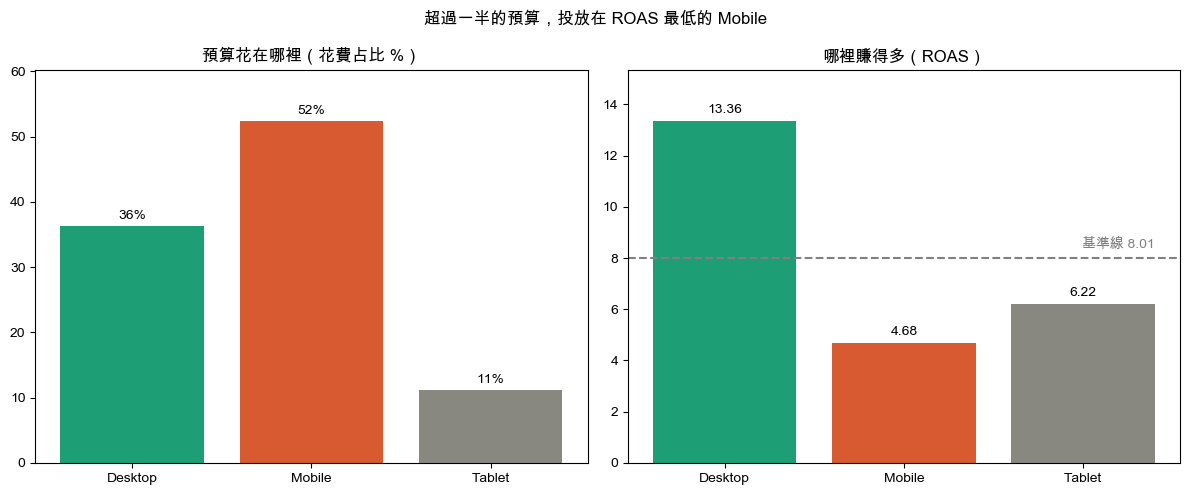

In [55]:
# 算出各裝置的花費占比和 ROAS
d = conv.groupby('device_type')[['ad_spend', 'revenue']].sum()
d['spend_share'] = d['ad_spend'] / d['ad_spend'].sum() * 100
d['ROAS'] = d['revenue'] / d['ad_spend']

colors = ['#1D9E75', '#D85A30', '#888780']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 左圖：花費占比
axes[0].bar(d.index, d['spend_share'], color=colors)
axes[0].set_title('預算花在哪裡（花費占比 %）')
for i, v in enumerate(d['spend_share']):
    axes[0].text(i, v + 1, f'{v:.0f}%', ha='center')

# 右圖：ROAS，加上基準線
axes[1].bar(d.index, d['ROAS'], color=colors)
axes[1].axhline(8.01, color='gray', linestyle='--')
axes[1].text(2.4, 8.4, '基準線 8.01', ha='right', color='gray')
axes[1].set_title('哪裡賺得多（ROAS）')
for i, v in enumerate(d['ROAS']):
    axes[1].text(i, v + 0.3, f'{v:.2f}', ha='center')

axes[0].set_ylim(0, d['spend_share'].max() * 1.15)
axes[1].set_ylim(0, d['ROAS'].max() * 1.15)

fig.suptitle('超過一半的預算，投放在 ROAS 最低的 Mobile')
plt.tight_layout()
plt.show()

- 假設不成立：Desktop 的 ROAS 最高（13.36），且 CVR 最高（0.0867 vs Mobile 0.0323），勝出主要來自 CVR。

In [16]:
# 各產業 × 裝置的 ROAS

device_industry = conv.groupby(['industry_vertical', 'device_type'])[['revenue', 'ad_spend']].sum()
device_industry['ROAS'] = device_industry['revenue'] / device_industry['ad_spend']
print(device_industry['ROAS'].unstack().round(2))

device_type        Desktop  Mobile  Tablet
industry_vertical                         
E-commerce            7.98    3.63    5.92
Education            13.17    4.20    5.75
Finance              24.43    6.66    8.04
Gaming                2.43    1.06    2.14
Healthcare           12.49    5.67    8.05
SaaS                 12.81    4.16    4.49


In [17]:
# 各產業 × 裝置的 campaign 數
print(conv.groupby(['industry_vertical', 'device_type']).size().unstack())

device_type        Desktop  Mobile  Tablet
industry_vertical                         
E-commerce             262     391     101
Education              127     158      25
Finance                145     256      42
Gaming                  43      70      19
Healthcare             192     324      63
SaaS                   267     395      66


In [18]:
# 各裝置花費占總花費的比例
print((conv.groupby('device_type')['ad_spend'].sum() / conv['ad_spend'].sum()).round(2))

device_type
Desktop    0.36
Mobile     0.52
Tablet     0.11
Name: ad_spend, dtype: float64


**產業檢查與花費占比**
- Desktop 在每個產業的 ROAS 都是最高，推測桌機介面較方便完成下單。
- Gaming 與 Education 的 Tablet 樣本不足（低於 30 筆），不下結論。
- Mobile 占總花費約 52%，ROAS 卻只有 4.68，低於基準線 8.01，代表超過一半的預算放在 ROAS 最差的裝置上。
- 建議逐步將部分 Mobile 預算移到 Desktop，並觀察 Desktop 的 CPC 與 CPA，避免受眾不足導致成本上升。
- 比較三個子問題的 ROAS 差距，應優先調整平台與裝置，素材的影響較小：
    - 平台：4.43 ～ 14.19，約 3.2 倍
    - 裝置：4.68 ～ 13.36，約 2.9 倍
    - 素材：6.08 ～ 8.63，約 1.4 倍

## 7. 子問題 4：加碼後的變化
**假設**：高 ROAS 組合的 ROAS 與 CPA 不會隨花費增加而變差，因為這些組合目前花費不大，離受眾飽和還遠。

分析對象為子問題 1、3 的贏家：Facebook 與 Desktop。在各自內部依花費分成 4 個級距，比較 ROAS 與 CPA 是否隨花費上升而變差。
（但只能看出相關，不能證明是花費造成 ROAS 變化。）

In [19]:
# 加碼 Facebook 後 ROAS、CPA 會不會變差？
fb = conv[conv['platform'] == 'Facebook'].copy()
fb['spend_level'] = pd.qcut(fb['ad_spend'], 4, labels=['小', '中小', '中大', '大'])

analyze_performance(fb, 'spend_level')

,campaigns,spend,ROAS,CPA,CPC,CVR,revenue_per_conversion,CTR
spend_level,,,,,,,,
小,180,38456.99,10.71,43.41,1.34,0.0310,464.98,0.0118
中小,179,128454.40,13.22,30.63,1.34,0.0438,404.94,0.0166
中大,179,310762.31,13.67,33.27,1.52,0.0457,454.78,0.0197
大,180,1325463.53,14.50,29.33,1.84,0.0627,425.30,0.0292


In [20]:
print(fb.groupby('spend_level', observed = True)['ad_spend'].agg(['min', 'max']).round(0))

                min      max
spend_level                 
小              17.0    403.0
中小            408.0   1072.0
中大           1092.0   2692.0
大            2695.0  49999.0


- 假設成立：隨花費增加，ROAS 從 10.71 升到 14.50，CPA 大致下降，單一 campaign 花費約 5 萬以內效率沒有變差，但超過 5 萬無資料，無法判斷。
- 但不能確定是「加碼讓 ROAS 變好」：可能是反向因果，成效好的 campaign 被投手加碼，因此花費較大。
- CPC 隨花費從 1.34 升到 1.84，代表加碼確實會讓點擊變貴，只是目前被 CVR 的提升抵銷，加碼 Facebook 時需同時觀察 CPC 與 CVR。

In [21]:
# 加碼 Desktop 後 ROAS、CPA 會不會變差？

desktop = conv[conv['device_type'] == 'Desktop'].copy()
desktop['spend_level'] = pd.qcut(desktop['ad_spend'], 4, labels=['小', '中小', '中大', '大'])

analyze_performance(desktop, 'spend_level')

,campaigns,spend,ROAS,CPA,CPC,CVR,revenue_per_conversion,CTR
spend_level,,,,,,,,
小,259,99742.96,15.55,26.10,1.47,0.0563,406.03,0.0169
中小,260,342993.26,17.04,26.78,1.90,0.0711,456.14,0.0213
中大,258,907361.07,12.43,35.55,2.62,0.0738,441.78,0.0219
大,259,3213688.06,13.16,33.03,3.17,0.0959,434.63,0.0280


In [22]:
print(desktop.groupby('spend_level', observed=True)['ad_spend'].agg(['min', 'max']).round(0))

                min      max
spend_level                 
小              24.0    740.0
中小            741.0   2106.0
中大           2113.0   4998.0
大            4999.0  49999.0


- 假設不成立：ROAS 先升後降，單一 campaign 花費超過約 2,100 元後效率下降。
- 但即使效率最差的組別，ROAS 仍有 12.43，高於基準線 8.01，也遠高於 Mobile 的 4.68，因此仍建議將部分 Mobile 預算移到 Desktop，可測試以新增 campaign（鎖定不同受眾）的方式加碼，讓單一 campaign 花費維持在約 2,100 元以內。
- CPC 從 1.47 升到 3.17（漲一倍多），CVR 從 0.056 升到 0.096（漲約 7 成），CPC 漲得比 CVR 快，因此 ROAS 下降，加碼 Desktop 時需同時觀察 CPC 與 CVR。

## 8. 驗證結論

### 檢查 1：Finance 的 Twitter
Twitter 在 Finance 的 ROAS 為 27.59，但只有 38 筆。
確認它是大部分 campaign 都表現好，還是被少數幾筆撐起來的。

In [62]:
# 只看 Finance
fin = conv[conv['industry_vertical'] == 'Finance']
tw = fin[fin['platform'] == 'Twitter']

# 檢查一：營收最大的 campaign 占比（38 筆平均分配的話，每筆約 2.6%）
rev = tw['revenue'].sort_values(ascending=False)
print('最大一筆占比：', round(rev.iloc[0] / rev.sum(), 2))
print('前三筆占比：', round(rev.iloc[:3].sum() / rev.sum(), 2))

# 檢查二：Finance 各平台單筆 ROAS 的中位數
print(fin.groupby('platform')['ROAS'].median().round(2))

最大一筆占比： 0.27
前三筆占比： 0.5
platform
Facebook       9.12
Google Ads     5.46
Instagram      9.67
LinkedIn       3.87
TikTok         8.95
Twitter       11.74
Name: ROAS, dtype: float64


1. 營收高度集中：前三筆 campaign 占 Twitter 在 Finance 營收的 50%，整體 ROAS 27.59 有一部分是被少數高營收 campaign 拉高的。
2. 改看中位數，Twitter 仍高於 Facebook（11.74 vs 9.12），代表一般的 Twitter campaign 也表現較好。
3. 但原本的差距（27.59 vs 21.72）被誇大了，且樣本只有 38 筆，建議以小額預算測試。

### 檢查 2：主要結論用中位數再看一次
整體 ROAS 會被花費大的 campaign 影響，因此改看單筆 ROAS 的中位數，確認 Facebook 和 Desktop 的優勢不是被少數 campaign 撐起來的。

In [24]:
# 各平台單筆 ROAS 的中位數
print(conv.groupby('platform')['ROAS'].median().round(2))

platform
Facebook      6.02
Google Ads    3.63
Instagram     4.15
LinkedIn      1.95
TikTok        5.36
Twitter       5.42
Name: ROAS, dtype: float64


In [25]:
# 各裝置單筆 ROAS 的中位數
print(conv.groupby('device_type')['ROAS'].median().round(2))

device_type
Desktop    7.74
Mobile     2.92
Tablet     3.64
Name: ROAS, dtype: float64


- 改用單筆 ROAS 中位數，排名不變：Facebook 仍為平台第一（6.02），Desktop 仍遠高於 Mobile（7.74 vs 2.92）。
- 加上樣本數充足（Facebook 718 筆、Desktop 1,036 筆、Mobile 1,594 筆），這兩個結論穩定，可作為預算調整的主要依據。

### 檢查 3：2024 與 2025 年分開看
要規劃的是下一波投放，確認結論在兩年都成立，而不是只在某一年成立。
2026 年只有 1 月資料，不納入比較。

In [63]:
conv = conv.copy()
conv['year'] = pd.to_datetime(conv['start_date']).dt.year

conv_y = conv[conv['year'].isin([2024, 2025])]

# 各年份 × 平台的 ROAS
year_platform = conv_y.groupby(['year', 'platform'])[['revenue', 'ad_spend']].sum()
year_platform['ROAS'] = year_platform['revenue'] / year_platform['ad_spend']
print(year_platform['ROAS'].unstack().round(2))

platform  Facebook  Google Ads  Instagram  LinkedIn  TikTok  Twitter
year                                                                
2024         11.18        6.25       7.47      4.21   11.83     9.68
2025         16.29        6.32       9.90      4.87   11.83    16.14


In [64]:
# 各年份 × 裝置的 ROAS
year_platform = conv_y.groupby(['year', 'device_type'])[['revenue', 'ad_spend']].sum()
year_platform['ROAS'] = year_platform['revenue'] / year_platform['ad_spend']
print(year_platform['ROAS'].unstack().round(2))

device_type  Desktop  Mobile  Tablet
year                                
2024           11.62    4.40    5.35
2025           14.97    5.07    8.08


1. Facebook 兩年都在前段班：2024 年第 2（11.18，與第 1 名 TikTok 11.83 相近），2025 年第 1（16.29，與 Twitter 16.14 幾乎平手）。
2. Desktop 兩年都遠勝 Mobile（2024 年約 2.6 倍，2025 年約 3 倍），結論穩定。
3. 2025 年多數平台與裝置的 ROAS 上升，可能反映整體環境變化，因此看相對排名：TikTok 兩年持平（11.83），排名從第 1 降到第 3；Facebook、Twitter 近一年表現較佳。

### 驗證總結：各結論的信心程度
- Facebook、Desktop：通過中位數與跨年度檢查，樣本充足 → 信心高，可作為主要預算調整方向
- Finance 的 Twitter：中位數仍較高，但營收集中在部分高成效 campaign 中、樣本只有 38 筆 → 信心中等，建議小額測試

## 9. 結論與建議

### 建議排序
1. Mobile 預算移到 Desktop：影響大（Mobile 占約 52% 預算）
2. Google Ads 預算移到 Facebook：影響大（CPC 差約 2.4 倍）
3. 素材依產業選擇：影響小（素材間 ROAS 差約 1.4 倍）
4. Finance 小額測試 Twitter

In [28]:
# 建議 1：Mobile 花費的 10% 移到 Desktop
mobile_spend = conv[conv['device_type'] == 'Mobile']['ad_spend'].sum()
move = mobile_spend * 0.1
print('移動金額：', round(move))

# 用 Desktop 加碼後最差的情況估算（中大組：ROAS 12.43、CPA 35.55）
# Mobile：ROAS 4.68、CPA 89.04
print('營收變化：', round(move * (12.43 - 4.68)))
print('轉換數變化：', round(move / 35.55 - move / 89.04))

移動金額： 657768
營收變化： 5097701
轉換數變化： 11115


### 建議 1：將部分 Mobile 預算移到 Desktop
- 【建議】將約 66 萬元（Mobile 花費的 10%）從 Mobile 移到 Desktop
- 【依據】Mobile 占總花費約 52%，ROAS 卻只有 4.68，低於基準線 8.01；Desktop ROAS 13.36，差距主要來自 CVR（0.0867 vs 0.0323）。此結論經中位數與 2024、2025 年分別檢查，結果一致。
- 【預期效果】以 Desktop 加碼後效率最差的情況估算，營收至少增加約 510 萬，轉換數增加約 1.1 萬筆。
- 【執行方式】單一 campaign 花費維持在約 2,100 元以內，以新增 campaign、鎖定不同受眾的方式加碼。
- 【驗證方式】先移 2 成（約 13 萬），測試 4 週，成功標準為 Desktop ROAS >= 12.43，且整體轉換數不減少。
- 【停損條件】若 Desktop CPA 超過 35.55，或 CPC 持續上升而 CVR 未跟上，停止加碼。
- 【限制】
    - 花費與 ROAS 的關係可能是反向因果：花費高的 campaign 可能是因為表現好才被加碼，因此實際效果可能低於估算。
    - 資料沒有觸及人數與頻率欄位，無法確認 Desktop 受眾能否承接新增預算，驗證期間需監控 CPC 與 ROAS。
    - 本分析以產業為單位，未考慮產品特性。若客戶產品需在手機上完成轉換（如 App 安裝、手機遊戲），移往 Desktop 可能不適用，需個別評估。

In [29]:
# 建議 2：Google Ads 花費的 10% 移到 Facebook
google_spend = conv[conv['platform'] == 'Google Ads']['ad_spend'].sum()
move = google_spend * 0.1
print('移動金額：', round(move))

# 用 Facebook 效率最差的情況估算（「小」組：ROAS 10.71、CPA 43.41）
# Google Ads：ROAS 6.37、CPA 66.92
print('營收變化：', round(move * (10.71 - 6.37)))
print('轉換數變化：', round(move / 43.41 - move / 66.92))

移動金額： 539695
營收變化： 2342277
轉換數變化： 4368


### 建議 2：將部分 Google Ads 預算移到 Facebook
- 【建議】將約 54 萬元（Google Ads 花費的 10%）從 Google Ads 移到 Facebook
- 【依據】Facebook ROAS 14.19，Google Ads 6.37。Facebook 勝出主要來自 CPC 低（1.72 vs 4.14），且在低 CPC 平台中 CVR 最高。
- 【預期效果】以 Facebook 效率最差的情況估算，營收至少增加約 234 萬，轉換數增加約 4,400 筆。
- 【驗證方式】先移 2 成（約 11 萬），測試 4 週，成功標準為 Facebook ROAS >= 10.71，且整體轉換數不減少。
- 【停損條件】若 Facebook CPA 超過 43.41，或 CPC 上升而 CVR 未跟上，停止加碼。
- 【限制】
    -  花費與 ROAS 的關係可能是反向因果：花費高的 campaign 可能是因為表現好才被加碼，因此實際效果可能低於估算。
    -  Google Ads 的 CVR 高於 Facebook（0.0619 vs 0.0568），可能因為多為搜尋廣告，受眾購買意願較高，這群人在 Facebook 上不一定觸及得到，減少 Google Ads 預算時，建議優先調降表現較差的 campaign，保留高意圖的搜尋廣告。
    -  Facebook 的 CPC 隨花費上升（1.34 → 1.84），目前被 CVR 提升抵銷，但大幅加碼後 CVR 不一定能持續跟上，需同時監控 CPC 與 CVR。

### 建議 3：素材依產業選擇
- 【建議】Healthcare 以 Video 為主；SaaS、Education 以 Carousel 為主；Finance 以 Image 為主；
  E-commerce 素材差異小，可優先選擇製作成本較低的素材；Gaming 樣本不足，暫不調整。
- 【依據】
  - Healthcare：Video 最好（10.64）
  - SaaS：Carousel 最好（11.57 vs Video 8.05）
  - Education：Carousel 最好（10.26）
  - Finance：排除樣本不足的 Text 後，Image 略勝（14.63 vs Video 13.46）
  - E-commerce：各素材差距很小
  - Gaming：樣本不足

### 建議 4：Finance 產業小額測試 Twitter
- 【建議】Finance 客戶可撥出少量預算（例如 Facebook 預算的 5% 以內）測試 Twitter，
  測試 4 週，與 Facebook 比較 ROAS。
- 【依據】
  - Twitter 在 Finance 的 ROAS 為 27.59，高於 Facebook 的 21.72
  - 改看中位數，Twitter 仍較高（11.74 vs 9.12），一般的 campaign 也表現較好
- 【注意】前三筆 campaign 占了 50% 營收，整體 ROAS 被少數 campaign 拉高；且只有 38 筆，樣本較小，建議小額先測試。